## **Tugas Besar Pengganti Ujian Tengah Semester (UTS), Semester Genap 2024/2025**
### Deadline: 13 November 2024, Pukul 5 Sore
##### Dosen: DKT, ITQ

---
***'Dengan ini kami menyatakan bahwa tugas ini dibuat sebenar-benarnya hasil kerjasama kami dalam kelompok. Kami menjunjung tinggi aspek kejujuran sehingga kami dapat pastikan hasil ini bukan berasal dari meniru/mencontek/meminta hasil/berdiskusi dengan kelompok lain, baik dalam satu kelas yang sama maupun berbeda'***

---


### **Penjelasan (harus dibaca dan dimengerti)**:
* Tugas besar harus dikerjakan menggunakan bahasa pemrograman `Python` dan *library* `Scikit-Learn`. Sebagai dasar, lihat **A.2. Dasar-dasar *Applications Programming Interface* (API) dari *Scikit-Learn*** pada **Chapter 3**
* Pada setiap bagian jawaban, anda bisa menambahkan cell `code` untuk kode maupun cell `Markdown` untuk penjelasan, sesuai dengan kebutuhan masing-masing.
* Dikumpulkan sesuai dengan tenggat waktu, setiap keterlambatan akan diberikan hukuman pengurangan 10 poin setiap kelipatan 15 menit.
* Dikerjakan dengan `Jupyter Lab` atau `Jupyter Notebook`, dan dikumpulkan dalam bentuk file dengan extension `.ipynb` yang digunakan pada `Jupyter Notebook/Jupyter Lab` (tidak boleh dalam format lain)

# 1. Metode Regresi (40 %)

**Prediksi Konsumsi Energi Bangunan Menggunakan Regresi**\
Ketentuan Dataset
Anda akan menggunakan dataset yang merepresentasikan **konsumsi energi pada bangunan** dengan fitur seperti **luas bangunan, jumlah lantai, usia bangunan, dan rata-rata jumlah penghuni**. Sebanyak 17 dataset telah disediakan, dan setiap kelompok harus menggunakan satu dataset sesuai dengan nomor kelompok masing-masing.

**Saat melakukan pemisahan data menjadi training dan testing:**
- Hitung **nilai `random_state`** dengan cara menjumlahkan digit terakhir dari setiap NIM anggota kelompok.
- Gunakan hasil penjumlahan ini sebagai nilai untuk parameter `random_state` dalam fungsi `train_test_split`.

Dengan metode ini, setiap kelompok akan memiliki pembagian data training dan testing yang unik dan konsisten sesuai NIM masing-masing. Misalnya, jika digit terakhir dari NIM anggota kelompok adalah **2, 9, dan 6**, maka jumlahnya adalah **17**. Maka nilai `random_state` yang digunakan adalah **17**.


Link download dataser [Dataset Regresi](https://telkomuniversityofficial-my.sharepoint.com/:f:/g/personal/istiqomah_telkomuniversity_ac_id/ErjC7U6KJGxDtMtgWqXzyysBL39nel2mcFrY514RMHh3LA?e=4f510h)

## Load Dataset

Load dataset sesuai ketentuan diatas, jika salah nilai untuk **nomer 1 = 0**.


## Dari Ketentuan Di Atas Maka
## **Nilai random_state kelompok kami 7+0+2+4 = 13**
## **Data set yang kami gunakan adalah Dataset_9**

In [1]:
import pandas as pd

data = pd.read_csv("Dataset_9.csv") #Ganti sesuai kelompok masing-masing
data.head()

,Building Area (sqm),Number of Floors,Age of Building (years),Average Occupants,Energy Consumption (kWh)
0,310.671153,3,30,67,320.377975
1,593.110861,3,2,21,470.717037
2,736.610463,4,15,14,519.284718
3,344.695821,4,47,69,311.058849
4,944.571651,4,27,50,604.511221


**Pertanyaan dan Instruksi**\
**1. Eksplorasi Data (10%)**\
a) Tampilkan statistik dasar dari dataset (mean, median, min, max untuk setiap fitur).\
b) Visualisasikan distribusi untuk setiap fitur dalam bentuk histogram.\
c) Tampilkan hubungan antara setiap fitur dengan variabel target (konsumsi energi) menggunakan plot scatter.

**2. Persiapan Data untuk Model Regresi (10%)**\
a) Pisahkan dataset menjadi data pelatihan dan pengujian (80% training, 20% testing). Tentukan nilai random_state sesuai ketentuan diatas.\

**3. Implementasi Model Regresi & Evaluasi Model(40%)**\
a) Gunakan tiga model regresi berikut dan latih masing-masing pada data pelatihan:\
- Linear Regression
- Regresi Polinomial
- Decision Tree Regression
- Random Forest\
Gunakan metrik Mean Absolute Error (MAE), Mean Squared Error (MSE), dan R² untuk mengevaluasi performa setiap model.

b) Bandingkan hasilnya dan tentukan model terbaik berdasarkan metrik yang diperoleh. Jelaskan alasan pemilihan tersebut.

**4. Analisis Feature Importance (30%)**\
a) Untuk model Random Forest Regression, analisis pentingnya fitur menggunakan metode feature importance. Visualisasikan hasilnya dalam bentuk bar chart.\
b) Diskusikan fitur mana yang paling berpengaruh terhadap konsumsi energi dan mengapa.\
c) Latih ulang dengan 2 fitur terbaik dengan semua metode regresi. Bandingkan hasilnya dengan model di nomer 3.

**5. Kesimpulan dan Rekomendasi (10%)**\
Tulis kesimpulan tentang temuan yang diperoleh dari analisis regresi ini. Rekomendasikan langkah-langkah untuk meningkatkan efisiensi energi bangunan berdasarkan fitur yang paling berpengaruh.

**1. Eksplorasi Data (10%)**

a) Tampilkan statistik dasar dari dataset (mean, median, min, max dan standard deviation untuk setiap fitur).

In [5]:
## Tampilkan semua statistik dasar dari fitur yang dipakai

import pandas as pd

df = pd.read_csv('Dataset_9.csv')

stats = df.describe().transpose()[['mean', '50%', 'min', 'max']]
stats.rename(columns={'50%': 'median'}, inplace=True)
print(stats)


                                mean      median         min         max
Building Area (sqm)       536.088779  536.730120  100.008366  995.166359
Number of Floors            2.568000    3.000000    1.000000    4.000000
Age of Building (years)    24.378000   25.000000    1.000000   49.000000
Average Occupants          51.456000   48.000000   10.000000   99.000000
Energy Consumption (kWh)  422.372330  430.357002   93.515162  766.689746


b) Visualisasikan distribusi untuk setiap fitur dalam bentuk histogram.

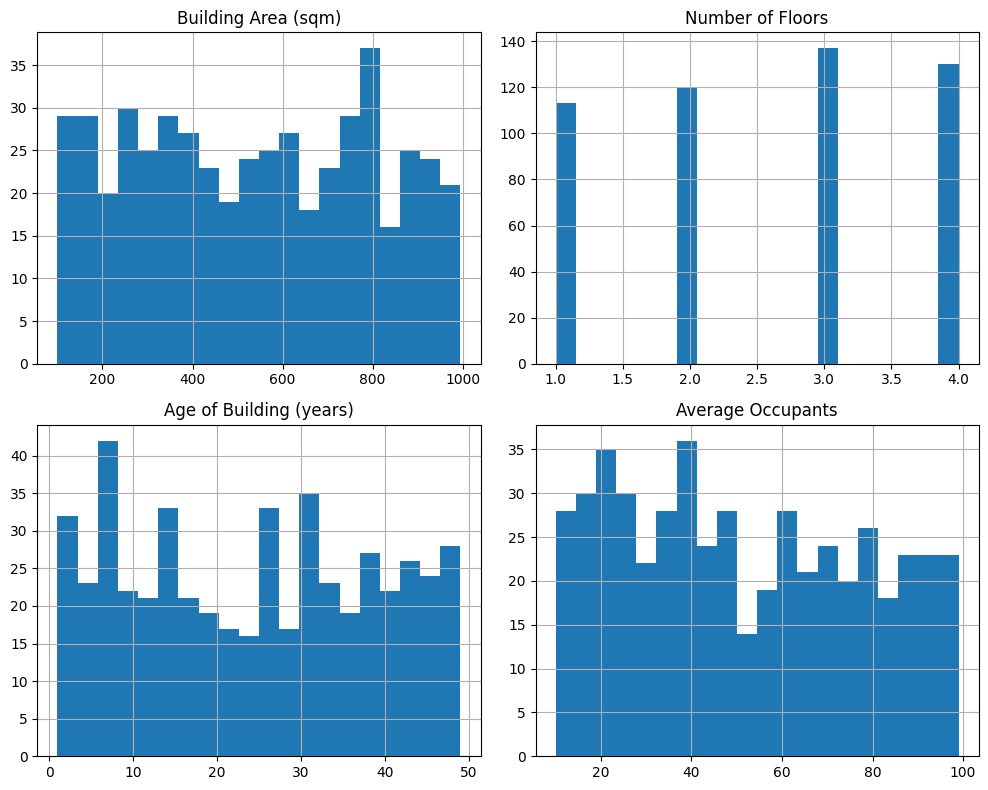

In [6]:
#Tampilkan semua fitur dalam bentuk histogram.

import matplotlib.pyplot as plt

df[['Building Area (sqm)', 'Number of Floors', 'Age of Building (years)', 'Average Occupants']].hist(bins=20, figsize=(10, 8))
plt.tight_layout()
plt.show()



c) Tampilkan hubungan antara setiap fitur dengan variabel target (konsumsi energi) menggunakan plot scatter.

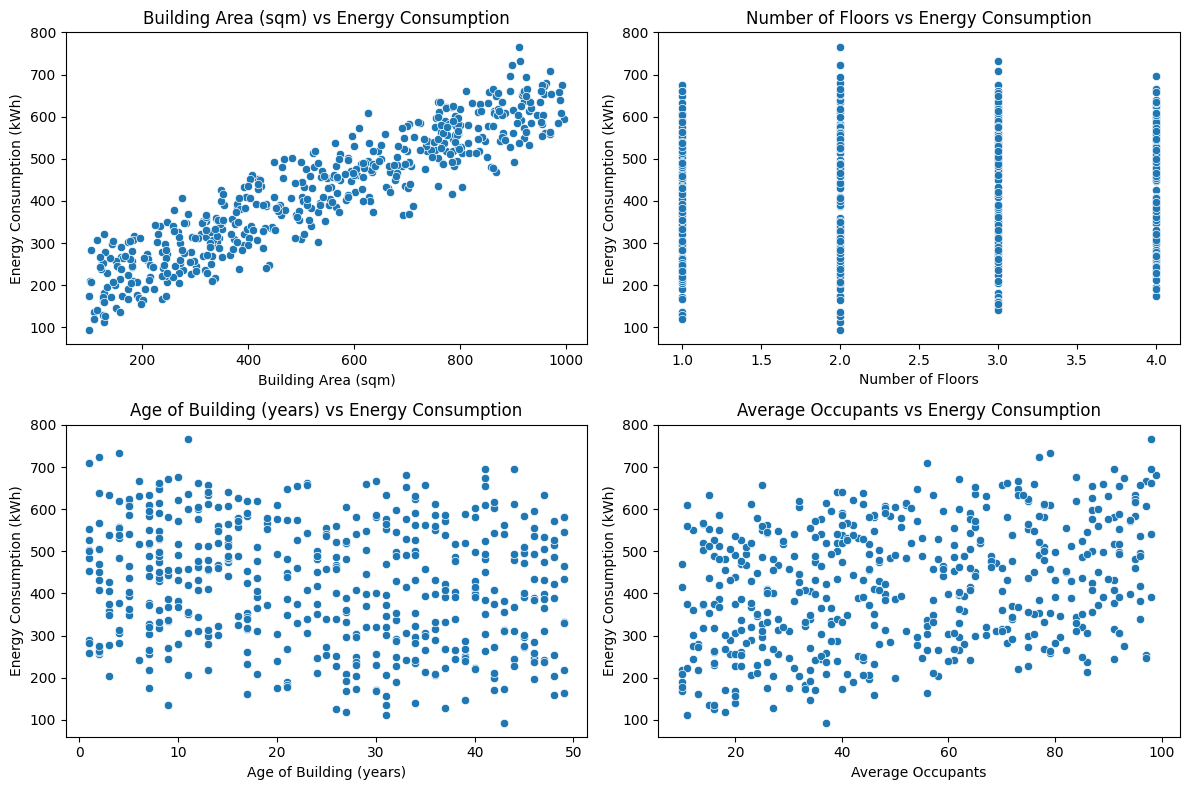

In [11]:
#Tampilkan semua fitur dalam bentuk plot scatter.
try:
    import seaborn as sns
except ImportError:
    !pip install seaborn

import seaborn as sns

plt.figure(figsize=(12, 8))

features = ['Building Area (sqm)', 'Number of Floors', 'Age of Building (years)', 'Average Occupants']
for i, feature in enumerate(features):
    plt.subplot(2, 2, i+1)
    sns.scatterplot(data=df, x=feature, y='Energy Consumption (kWh)')
    plt.title(f'{feature} vs Energy Consumption')

plt.tight_layout()
plt.show()



**2. Persiapan Data untuk Model Regresi (10%)**

a) Pisahkan dataset menjadi data pelatihan dan pengujian (90% training, 10% testing). Tentukan nilai random_state sesuai ketentuan diatas. Jika random_state salah makan nilai dari soal ini  = 0.

In [13]:
#Split dataset

import pandas as pd
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('Dataset_9.csv')

dataset.fillna(dataset.mean(), inplace=True)

X = dataset[['Building Area (sqm)', 'Number of Floors', 'Age of Building (years)', 'Average Occupants']]
y = dataset['Energy Consumption (kWh)']

random_state = 13  # Sesuai ketentuan soal, NIM : 7+0+2+4 = 13
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=random_state)

print(f"Data pelatihan: {X_train.shape[0]} sampel")
print(f"Data pengujian: {X_test.shape[0]} sampel")

print("\nContoh data pelatihan (X_train):")
print(X_train.head())

print("\nContoh data pengujian (X_test):")
print(X_test.head())


Data pelatihan: 450 sampel
Data pengujian: 50 sampel

Contoh data pelatihan (X_train):
     Building Area (sqm)  Number of Floors  Age of Building (years)  \
347           341.086884                 4                       17   
287           159.838123                 2                       32   
67            628.587829                 2                       40   
71            349.126117                 4                       17   
93            379.023415                 4                       10   

     Average Occupants  
347                 16  
287                 72  
67                  26  
71                  87  
93                  31  

Contoh data pengujian (X_test):
     Building Area (sqm)  Number of Floors  Age of Building (years)  \
0             310.671153                 3                       30   
334           245.509612                 4                        2   
33            350.104958                 2                       49   
264           665.7

**3. Implementasi Model Regresi & Evaluasi Model(40%)**

a.1)Regresi Linier

In [27]:
#Regresi Linier
#Import library metode machine learning.


#Siapkan data yang akan ditraining fitur (semua fitur) dan output 

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode Regresi Linier. 
#Lakukan berulang kali process fitting dengan mengganti hyperparameter dan mengukur kinerjanya sehingga mendaparkan model terbaik regresi linier.
#ukur kinerja setiap model pada setiap trainig dengan MSE,RMSE, R2.


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from math import sqrt

dataset = pd.read_csv('Dataset_9.csv')

dataset.fillna(dataset.mean(), inplace=True)

X = dataset[['Building Area (sqm)', 'Number of Floors', 'Age of Building (years)', 'Average Occupants']]
y = dataset['Energy Consumption (kWh)']

random_state = 13  
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=random_state)

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluasi model dengan MSE, RMSE, dan R2
lin_mse = mean_squared_error(y_test, y_pred)
lin_rmse = sqrt(lin_mse)
lin_r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error (MSE): {lin_mse}')
print(f'Root Mean Squared Error (RMSE): {lin_rmse}')
print(f'R-squared (R2): {lin_r2}')

Mean Squared Error (MSE): 438.95693545778687
Root Mean Squared Error (RMSE): 20.951299135323016
R-squared (R2): 0.9772033714656784


a.2) Regresi Polinomial

In [28]:
#Regresi Polinomial
#Import library metode machine learning.


#Siapkan data yang akan ditraining fitur (semua fitur) dan output 

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode Regresi Polinomial. 
#Lakukan berulang kali process fitting dengan mengganti hyperparameter dan mengukur kinerjanya sehingga mendaparkan model terbaik regresi linier.
#ukur kinerja setiap model pada setiap trainig dengan MSE,RMSE, R2.

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score
from math import sqrt

dataset = pd.read_csv('Dataset_9.csv')

dataset.fillna(dataset.mean(), inplace=True)

X = dataset[['Building Area (sqm)', 'Number of Floors', 'Age of Building (years)', 'Average Occupants']]
y = dataset['Energy Consumption (kWh)']

random_state = 13  # Sesuai ketentuan soal
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=random_state)

degree = 2 
poly = PolynomialFeatures(degree=degree)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LinearRegression()

model.fit(X_train_poly, y_train)

y_pred = model.predict(X_test_poly)

# Evaluasi model dengan MSE, RMSE, dan R2
poly_mse = mean_squared_error(y_test, y_pred)
poly_rmse = sqrt(poly_mse)
poly_r2 = r2_score(y_test, y_pred)

print(f'Degree Polynomial: {degree}')
print(f'Mean Squared Error (MSE): {poly_mse}')
print(f'Root Mean Squared Error (RMSE): {poly_rmse}')
print(f'R-squared (R2): {poly_r2}')



Degree Polynomial: 2
Mean Squared Error (MSE): 463.8235389262593
Root Mean Squared Error (RMSE): 21.536562839187205
R-squared (R2): 0.9759119583989504


a.3) Decision Tree Regression

In [31]:
#Decision Tree Regression
#Import library metode machine learning.


#Siapkan data yang akan ditraining fitur (semua fitur) dan output  

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode Decision Tree Regresi. 
#Lakukan berulang kali process fitting dengan mengganti hyperparameter dan mengukur kinerjanya sehingga mendaparkan model terbaik regresi linier.
#ukur kinerja setiap model pada setiap trainig dengan MSE,RMSE, R2.

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
from math import sqrt

dataset = pd.read_csv('Dataset_9.csv')

dataset.fillna(dataset.mean(), inplace=True)

X = dataset[['Building Area (sqm)', 'Number of Floors', 'Age of Building (years)', 'Average Occupants']]
y = dataset['Energy Consumption (kWh)']

random_state = 13  
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=random_state)

model = DecisionTreeRegressor(random_state=random_state)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluasi model dengan MSE, RMSE, dan R2
dt_mse = mean_squared_error(y_test, y_pred)
dt_rmse = sqrt(dt_mse)
dt_r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error (MSE): {dt_mse}')
print(f'Root Mean Squared Error (RMSE): {dt_rmse}')
print(f'R-squared (R2): {dt_r2}')

# Hyperparameter Tuning untuk menguji dengan kedalaman pohon yang berbeda
for max_depth in [3, 5, 10, 15, 20]:  # kedalaman pohon yang dicoba
    model = DecisionTreeRegressor(random_state=random_state, max_depth=max_depth)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    dt_mse = mean_squared_error(y_test, y_pred)
    dt_rmse = sqrt(dt_mse)
    dt_r2 = r2_score(y_test, y_pred)
    
    print(f'\nModel dengan max_depth={max_depth}:')
    print(f'Mean Squared Error (MSE): {dt_mse}')
    print(f'Root Mean Squared Error (RMSE): {dt_rmse}')
    print(f'R-squared (R2): {dt_r2}')


Mean Squared Error (MSE): 1651.8466164919912
Root Mean Squared Error (RMSE): 40.642915944749724
R-squared (R2): 0.9142136034994593

Model dengan max_depth=3:
Mean Squared Error (MSE): 2177.2380775579622
Root Mean Squared Error (RMSE): 46.660883806009956
R-squared (R2): 0.8869281160050323

Model dengan max_depth=5:
Mean Squared Error (MSE): 1520.9961541882615
Root Mean Squared Error (RMSE): 38.999950694690135
R-squared (R2): 0.92100914342998

Model dengan max_depth=10:
Mean Squared Error (MSE): 1766.0384085270814
Root Mean Squared Error (RMSE): 42.024259761798085
R-squared (R2): 0.9082832088424582

Model dengan max_depth=15:
Mean Squared Error (MSE): 1651.8466164919912
Root Mean Squared Error (RMSE): 40.642915944749724
R-squared (R2): 0.9142136034994593

Model dengan max_depth=20:
Mean Squared Error (MSE): 1651.8466164919912
Root Mean Squared Error (RMSE): 40.642915944749724
R-squared (R2): 0.9142136034994593


a.4) Random Forest Regression

In [32]:
#Random Forest Regression
#Import library metode machine learning.


#Siapkan data yang akan ditraining fitur (semua fitur) dan output  

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode Random Forest Regression. 
#Lakukan berulang kali process fitting dengan mengganti hyperparameter dan mengukur kinerjanya sehingga mendaparkan model terbaik regresi linier.
#ukur kinerja setiap model pada setiap trainig dengan MSE,RMSE, R2.


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from math import sqrt

dataset = pd.read_csv('Dataset_9.csv')

dataset.fillna(dataset.mean(), inplace=True)

X = dataset[['Building Area (sqm)', 'Number of Floors', 'Age of Building (years)', 'Average Occupants']]
y = dataset['Energy Consumption (kWh)']

random_state = 13  
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=random_state)

model = RandomForestRegressor(random_state=random_state)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluasi model dengan MSE, RMSE, dan R2
rf_mse = mean_squared_error(y_test, y_pred)
rf_rmse = sqrt(rf_mse)
rf_r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error (MSE): {rf_mse}')
print(f'Root Mean Squared Error (RMSE): {rf_rmse}')
print(f'R-squared (R2): {rf_r2}')

# Hyperparameter Tuning untuk menguji dengan berbagai jumlah estimator (n_estimators) dan kedalaman pohon (max_depth)
for n_estimators in [10, 50, 100, 200]:  # jumlah estimator yang dicoba
    for max_depth in [3, 5, 10, 15, 20]:  # kedalaman pohon yang dicoba
        model = RandomForestRegressor(random_state=random_state, n_estimators=n_estimators, max_depth=max_depth)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        rf_mse = mean_squared_error(y_test, y_pred)
        rf_rmse = sqrt(rf_mse)
        rf_r2 = r2_score(y_test, y_pred)
        
        print(f'\nModel dengan n_estimators={n_estimators}, max_depth={max_depth}:')
        print(f'Mean Squared Error (MSE): {rf_mse}')
        print(f'Root Mean Squared Error (RMSE): {rf_rmse}')
        print(f'R-squared (R2): {rf_r2}')


Mean Squared Error (MSE): 799.6101775555475
Root Mean Squared Error (RMSE): 28.2773792554322
R-squared (R2): 0.9584733382308075

Model dengan n_estimators=10, max_depth=3:
Mean Squared Error (MSE): 1464.5078122412187
Root Mean Squared Error (RMSE): 38.268888306837695
R-squared (R2): 0.9239427882681541

Model dengan n_estimators=10, max_depth=5:
Mean Squared Error (MSE): 1014.349472647869
Root Mean Squared Error (RMSE): 31.84885355311662
R-squared (R2): 0.9473211464176484

Model dengan n_estimators=10, max_depth=10:
Mean Squared Error (MSE): 924.0626975009837
Root Mean Squared Error (RMSE): 30.39839958782343
R-squared (R2): 0.9520100666927976

Model dengan n_estimators=10, max_depth=15:
Mean Squared Error (MSE): 916.1823222438438
Root Mean Squared Error (RMSE): 30.268503799227403
R-squared (R2): 0.9524193232119155

Model dengan n_estimators=10, max_depth=20:
Mean Squared Error (MSE): 916.1823222438438
Root Mean Squared Error (RMSE): 30.268503799227403
R-squared (R2): 0.9524193232119155


b) Bandingkan hasilnya dan tentukan model terbaik berdasarkan metrik yang diperoleh. Jelaskan alasan pemilihan tersebut.

In [ ]:
#Analisis dengan memilih model terbaik dan parameter apa yang diperhatikan

# Hasil evaluasi model sebelumnya disimpan dalam sebuah dictionary
model_results = {
    'Linear Regression': {'MSE': lin_mse, 'RMSE': lin_rmse, 'R2': lin_r2},
    'Polynomial Regression (degree=2)': {'MSE': poly_mse, 'RMSE': poly_rmse, 'R2': poly_r2},
    'Decision Tree Regression': {'MSE': dt_mse, 'RMSE': dt_rmse, 'R2': dt_r2},
    'Random Forest Regression': {'MSE': rf_mse, 'RMSE': rf_rmse, 'R2': rf_r2}
}

for model_name, metrics in model_results.items():
    print(f'{model_name}:')
    print(f'  MSE: {metrics["MSE"]:.4f}')
    print(f'  RMSE: {metrics["RMSE"]:.4f}')
    print(f'  R²: {metrics["R2"]:.4f}')
    print('-' * 40)

# Tentukan model terbaik berdasarkan MSE, RMSE, dan R2
# Model terbaik adalah yang memiliki MSE dan RMSE terendah, dan R2 tertinggi.
best_model = min(model_results, key=lambda model: model_results[model]['MSE'])  
print(f'Model Terbaik Berdasarkan MSE: {best_model}')

best_r2_model = max(model_results, key=lambda model: model_results[model]['R2'])
print(f'Model Terbaik Berdasarkan R²: {best_r2_model}')


Linear Regression:
  MSE: 438.9569
  RMSE: 20.9513
  R²: 0.9772
----------------------------------------
Polynomial Regression (degree=2):
  MSE: 463.8235
  RMSE: 21.5366
  R²: 0.9759
----------------------------------------
Decision Tree Regression:
  MSE: 1651.8466
  RMSE: 40.6429
  R²: 0.9142
----------------------------------------
Random Forest Regression:
  MSE: 794.3822
  RMSE: 28.1848
  R²: 0.9587
----------------------------------------
Model Terbaik Berdasarkan MSE: Linear Regression
Model Terbaik Berdasarkan R²: Linear Regression


**4. Analisis Feature Importance (30%)**

a) Untuk model Random Forest Regression, analisis pentingnya fitur menggunakan metode feature importance. Visualisasikan hasilnya dalam bentuk bar chart.


Skor Feature Importance:
Building Area (sqm): 0.8768
Average Occupants: 0.0792
Age of Building (years): 0.0377
Number of Floors: 0.0064


C:\Users\vnalv\AppData\Local\Temp\ipykernel_24928\3378434154.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


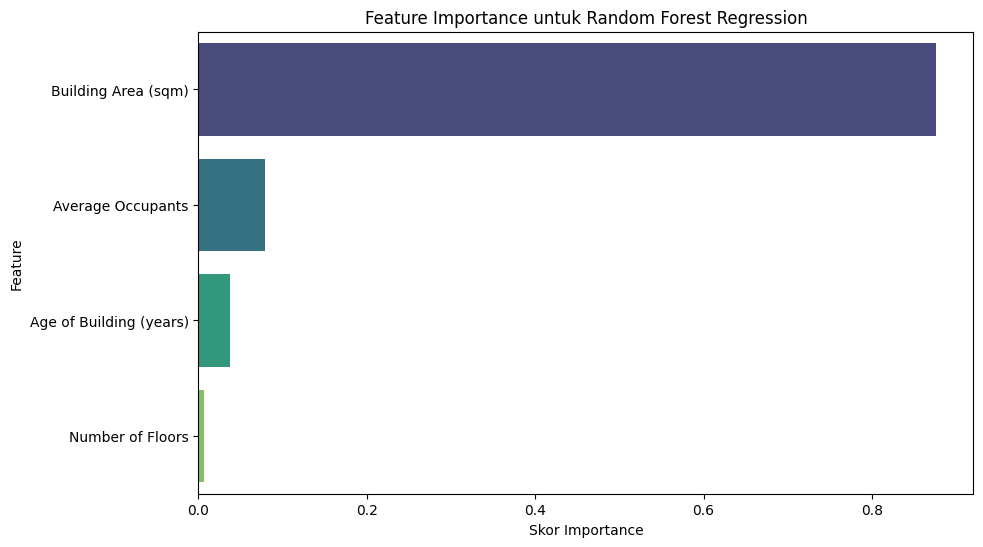

In [2]:
#Random Forest Regression
#Import library metode machine learning.


#Siapkan data yang akan ditraining fitur (semua fitur) dan output  

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode random forest regression
#Keluarkan nilai fitur terpenting dan buat visualisasi hasil dengan chat bar.


import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Dataset_9.csv')
X = df.drop(columns=['Energy Consumption (kWh)']) 
y = df['Energy Consumption (kWh)'] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

rf_model = RandomForestRegressor(random_state=13)
rf_model.fit(X_train, y_train)

feature_importances = rf_model.feature_importances_

# DataFrame untuk hasil fitur penting
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

print("Skor Feature Importance:")
for feature, score in zip(feature_importance_df['Feature'], feature_importance_df['Importance']):
    print(f"{feature}: {score:.4f}")

# Bar Chart Fitur Penting
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('Feature Importance untuk Random Forest Regression')
plt.xlabel('Skor Importance')
plt.ylabel('Feature')
plt.show()

b) Diskusikan fitur mana yang paling berpengaruh terhadap konsumsi energi dan mengapa.

**Jawab analisis fitur terbaik disini**

 Berdasarkan nilai skor di atas, dapat dilihat bahwa luas bangunan (Building Area) adalah faktor yang paling berpengaruh terhadap konsumsi energi, diikuti oleh jumlah rata-rata penghuni (Average Occupants), sementara usia bangunan (Age of Building) dan jumlah lantai (Number of Floors) memiliki pengaruh yang lebih kecil.
 
 1. Building Area (sqm) memiliki pengaruh terbesar terhadap konsumsi energi.\
    Luas bangunan memiliki pengaruh terbesar terhadap konsumsi energi. Semakin besar bangunannya, semakin banyak energi yang diperlukan untuk hal-hal seperti pencahayaan, pemanasan, atau pendinginan. Karena itu, tidak mengherankan jika luas bangunan menjadi faktor utama yang menentukan berapa banyak energi yang akan digunakan.
    
 
 2. Average Occupants juga berpengaruh, meskipun tidak sebesar luas bangunan.\
    Jumlah rata-rata orang yang ada di dalam bangunan juga berpengaruh pada konsumsi energi. Semakin banyak orang, semakin tinggi kebutuhan untuk pencahayaan, pendinginan, dan penggunaan peralatan lain. Ini membuat fitur ini cukup penting, meskipun tidak sekuat luas bangunan.
 
 3. Age of Building (years) memiliki pengaruh yang lebih kecil.\
    Usia bangunan berpengaruh lebih kecil. Bangunan yang lebih tua mungkin membutuhkan lebih banyak energi karena sistemnya mungkin kurang efisien dibandingkan bangunan yang lebih baru. Namun, pengaruhnya tidak sebesar luas bangunan atau jumlah penghuni.
 
 4. Number of Floors memiliki pengaruh paling kecil.\
   Pengaruh dari jumlah lantai ternyata sangat kecil. Ini mungkin karena luas lantai lebih menentukan kebutuhan energi daripada jumlah lantainya. Jika bangunan memiliki lantai lebih banyak tetapi luasnya sama, energi yang dibutuhkan tidak akan jauh berbeda.
 
## Kesimpulan:
Dari hasil ini, Luas Bangunan adalah faktor yang paling penting dalam menentukan konsumsi energi. Jika ingin mengoptimalkan atau memperkirakan kebutuhan energi, kita perlu fokus pada luas bangunan, karena faktor lain seperti jumlah penghuni juga berpengaruh tetapi lebih kecil.


c) Latih ulang dengan 2 fitur terbaik dengan semua metode regresi. Bandingkan hasilnya dengan model di nomer 3.

In [ ]:
#Semua model regresi
#Import library metode machine learning.


#Siapkan data yang akan ditraining 2 fitur terbaik dan output  

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode Semua model regresi
#Lakukan berulang kali process fitting dengan mengganti hyperparameter dan mengukur kinerjanya sehingga mendaparkan model terbaik regresi linier.
#ukur kinerja setiap model pada setiap trainig dengan MSE,RMSE, R2.


import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

df = pd.read_csv('Dataset_9.csv')
# dua fitur terbaik: Building Area (sqm) dan Average Occupants
X = df[['Building Area (sqm)', 'Average Occupants']]  
y = df['Energy Consumption (kWh)'] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

models = {
    'Linear Regression': LinearRegression(),
    'Polynomial Regression (degree=2)': PolynomialFeatures(degree=2),
    'Decision Tree Regression': DecisionTreeRegressor(random_state=13),
    'Random Forest Regression': RandomForestRegressor(random_state=13)
}

model_results = {}

# training dan evaluasi model
for model_name, model in models.items():
    if model_name == 'Polynomial Regression (degree=2)':
        # Transformasi fitur
        poly = model
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)
        
        # pake linearregression untuk fitting dengan fitur polinomial
        model_lr = LinearRegression()
        model_lr.fit(X_train_poly, y_train)
        y_pred = model_lr.predict(X_test_poly)
        
    else:
        # fitting model lainnya langsung dengan data asli
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    
    # hitung MSE, RMSE, dan R2
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    model_results[model_name] = {'MSE': mse, 'RMSE': rmse, 'R2': r2}

for model_name, metrics in model_results.items():
    print(f'{model_name}:')
    print(f'  MSE: {metrics["MSE"]:.4f}')
    print(f'  RMSE: {metrics["RMSE"]:.4f}')
    print(f'  R²: {metrics["R2"]:.4f}')
    print('-' * 40)

best_model = min(model_results, key=lambda model: model_results[model]['MSE'])
print(f'Model Terbaik Berdasarkan MSE: {best_model}')

best_r2_model = max(model_results, key=lambda model: model_results[model]['R2'])
print(f'Model Terbaik Berdasarkan R2: {best_r2_model}')


Linear Regression:
  MSE: 921.6481
  RMSE: 30.3587
  R²: 0.9521
----------------------------------------
Polynomial Regression (degree=2):
  MSE: 907.9386
  RMSE: 30.1320
  R²: 0.9528
----------------------------------------
Decision Tree Regression:
  MSE: 2238.4319
  RMSE: 47.3121
  R²: 0.8838
----------------------------------------
Random Forest Regression:
  MSE: 1251.7237
  RMSE: 35.3797
  R²: 0.9350
----------------------------------------
Model Terbaik Berdasarkan MSE: Polynomial Regression (degree=2)
Model Terbaik Berdasarkan R2: Polynomial Regression (degree=2)


Linear Regression:
  MSE: 921.6481
  RMSE: 30.3587
  R2: 0.9521
----------------------------------------
Polynomial Regression (degree=2):
  MSE: 907.9386
  RMSE: 30.1320
  R2: 0.9528
----------------------------------------
Decision Tree Regression:
  MSE: 2238.4319
  RMSE: 47.3121
  R2: 0.8838
----------------------------------------
Random Forest Regression:
  MSE: 1251.7237
  RMSE: 35.3797
  R2: 0.9350
----------------------------------------


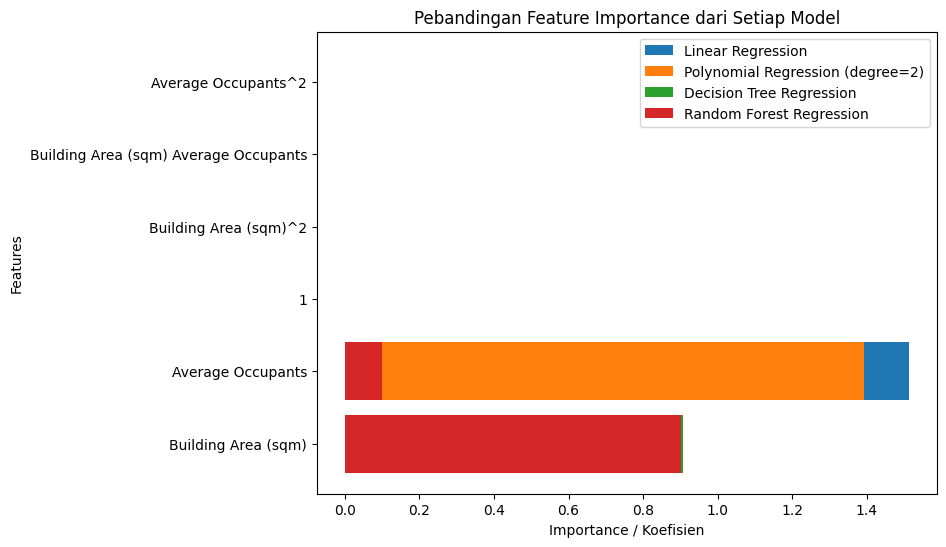

In [18]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('Dataset_9.csv')

X = df[['Building Area (sqm)', 'Average Occupants']]
y = df['Energy Consumption (kWh)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

model_results = {}

# model yang akan diuji
models = {
    'Linear Regression': LinearRegression(),
    'Polynomial Regression (degree=2)': PolynomialFeatures(degree=2),
    'Decision Tree Regression': DecisionTreeRegressor(random_state=13),
    'Random Forest Regression': RandomForestRegressor(random_state=13)
}

# training model dan evaluasi
for model_name, model in models.items():
    if model_name == 'Polynomial Regression (degree=2)':
        poly = model
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)
        
        #  Linear Regression untuk fitting dengan fitur polinomial
        model_lr = LinearRegression()
        model_lr.fit(X_train_poly, y_train)
        y_pred = model_lr.predict(X_test_poly)
        
        coefficients = model_lr.coef_
        feature_names = poly.get_feature_names_out(input_features=X.columns)
    
    elif model_name == 'Linear Regression':
        # Linear Regression dengan data asli
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        # Koefisien fitur pada model Linear Regression
        coefficients = model.coef_
        feature_names = X.columns
    
    else:
        # fitting model lainnya langsung dengan data asli
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        if model_name in ['Decision Tree Regression', 'Random Forest Regression']:
            # ambil fitur untuk Decision Tree dan Random Forest
            feature_importance = model.feature_importances_
            feature_names = X.columns
            coefficients = feature_importance
    
    # Hitung MSE, RMSE, dan R2
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    model_results[model_name] = {'MSE': mse, 'RMSE': rmse, 'R2': r2, 'Coefficients': coefficients, 'Feature Names': feature_names}

# hasil evaluasi model
for model_name, metrics in model_results.items():
    print(f'{model_name}:')
    print(f'  MSE: {metrics["MSE"]:.4f}')
    print(f'  RMSE: {metrics["RMSE"]:.4f}')
    print(f'  R2: {metrics["R2"]:.4f}')
    print('-' * 40)

plt.figure(figsize=(8, 6))

# nentuin koefisien atau fitur penting dari model terbaik
for model_name, metrics in model_results.items():
    coefficients = metrics['Coefficients']
    feature_names = metrics['Feature Names']
    
    plt.barh(feature_names, coefficients, label=model_name)

plt.xlabel('Importance / Koefisien')
plt.ylabel('Features')
plt.title('Pebandingan Feature Importance dari Setiap Model')
plt.legend()
plt.show()


**Bandingkan mana model dan fitur terbaik**

## Kesimpulan:
Model terbaik berdasarkan MSE dan R2: **Polynomial Regression dengan derajat kedua**.\
Fitur terbaik: Berdasarkan analisis sebelumnya, **Average Occupants dan juga fitur Building Area (sqm)** adalah fitur yang paling berpengaruh terhadap konsumsi energi.
Di mana **Average Occupants** memiliki pengaruh yang lebih besar terhadap Energy Consumption (kWh) dalam model ini.\
Hal ini mungkin karena semakin banyak penghuni, konsumsi energi cenderung meningkat (seperti untuk pemanas, pendingin udara, dan peralatan listrik), sementara luas bangunan memiliki dampak yang lebih kecil. Model ini menangkap hubungan yang lebih kompleks antara fitur dan konsumsi energi.

**5. Kesimpulan dan Rekomendasi (10%)**\
Tulis kesimpulan tentang temuan yang diperoleh dari analisis regresi ini. Rekomendasikan langkah-langkah untuk meningkatkan efisiensi energi bangunan berdasarkan fitur yang paling berpengaruh.

**Jawab kesimpulan dan rekomendasi disini**

### Kesimpulan
Berdasarkan hasil analisis regresi yang dilakukan, model Polynomial Regression (degree=2) terbukti menjadi yang terbaik berdasarkan metrik MSE dan R2. Setelah melakukan pelatihan dengan dua fitur terbaik (yaitu Building Area (sqm) dan Average Occupants), model ini menunjukkan MSE terkecil (907.9386) dan R2 tertinggi (0.9528), yang mengindikasikan kinerja terbaik dalam memprediksi Energy Consumption (kWh). Selain itu, fitur Average Occupants menunjukkan pengaruh yang lebih besar terhadap konsumsi energi dibandingkan building area, yang tercermin dalam koefisien polinomial yang lebih tinggi untuk Average Occupants.

### Rekomendasi
1. Optimasi Jumlah Penghuni (Average Occupants):\
Karena average occupants lebih mempengaruhi konsumsi energi, salah satu cara untuk menghemat energi adalah dengan menyesuaikan jumlah penghuni di dalam bangunan. Misalnya, dengan mengurangi jumlah penghuni yang tidak perlu atau menggunakan sistem yang mengatur penggunaan energi berdasarkan berapa banyak orang yang ada di dalam ruangan.
2. Desain Bangunan dengan Fokus pada Penghuni:\
Meskipun building area juga berpengaruh, desain bangunan yang efisien, seperti memanfaatkan pencahayaan alami dan ventilasi yang baik, bisa membantu mengurangi penggunaan energi.
3. Penerapan Sistem Energi Terbarukan:\
Untuk mengurangi penggunaan energi, bangunan bisa menggunakan sumber energi terbarukan seperti panel surya. Ini bisa membantu mengurangi ketergantungan pada energi dari listrik konvensional yang lebih mahal dan kurang ramah lingkungan.
4. Penerapan Teknologi Smart Building:\
Menggunakan teknologi pintar di dalam bangunan, seperti sistem yang bisa menyesuaikan pemakaian energi berdasarkan jumlah penghuni, bisa membantu menghemat energi dan membuat pemakaian lebih efisien.

# 2. Metode Klasifikasi dan Ensamble Learning (60%)

**Overview Dataset**

Dataset ini dirancang untuk peramalan cuaca, terdiri dari 500 contoh data dengan 4 fitur utama yang digunakan untuk memprediksi kondisi cuaca. Setiap contoh data memiliki label yang menunjukkan salah satu dari empat kondisi cuaca yang mungkin.

### Fitur dan Output

- **Temperature (°C)**: Suhu luar ruangan dalam derajat Celsius, berkisar antara -15°C hingga 40°C.
- **Humidity (%)**: Tingkat kelembaban udara dalam persentase, menunjukkan kadar uap air di atmosfer.
- **Wind Speed (km/h)**: Kecepatan angin dalam kilometer per jam, yang dapat mempengaruhi kondisi cuaca tertentu.
- **Pressure (hPa)**: Tekanan atmosfer dalam satuan hectopascal, yang memengaruhi pola cuaca dan kemungkinan terjadinya presipitasi.

- **Output (Kondisi Cuaca)**: Variabel target dengan empat kelas:
  - **0: Clear** - Langit cerah, biasanya terkait dengan suhu sedang, kelembaban rendah, dan tekanan stabil.
  - **1: Cloudy** - Kondisi berawan, sering kali terkait dengan suhu sedang, kelembaban tinggi, dan tekanan yang stabil atau sedikit lebih rendah.
  - **2: Rainy** - Presipitasi dalam bentuk hujan, biasanya terjadi pada suhu sedang, kelembaban tinggi, dan tekanan yang lebih renda|h.
  - **3: Snowing** - Presipitasi dalam bentuk salju, biasanya terjadi pada suhu sekitar atau di bawah 0°C, kelembaban tinggi, dan tekanan sedang hingga rendah.

Dataset ini dapat digunakan untuk membangun model klasifikasi cuaca, membantu memahami pola meteorologis, dan mendukung model peramalan yang akurat.

**Saat melakukan pemisahan data menjadi training dan testing:**
- Hitung **nilai `random_state`** dengan cara menjumlahkan digit terakhir dari setiap NIM anggota kelompok.
- Gunakan hasil penjumlahan ini sebagai nilai untuk parameter `random_state` dalam fungsi `train_test_split`.

Dengan metode ini, setiap kelompok akan memiliki pembagian data training dan testing yang unik dan konsisten sesuai NIM masing-masing. Misalnya, jika digit terakhir dari NIM anggota kelompok adalah **2, 9, dan 6**, maka jumlahnya adalah **17**. Maka nilai `random_state` yang digunakan adalah **17**.



Link download dataser [Dataset Klasifikasi](https://telkomuniversityofficial-my.sharepoint.com/:f:/g/personal/istiqomah_telkomuniversity_ac_id/Eud9Km79RyhFs-ZeXydin9UBX8ucLCdFmfZLbFFAi1aKRA?e=oKcgaI)

## Load Dataset

Load dataset sesuai ketentuan diatas, jika salah nilai untuk **nomer 1 = 0**.


### **PERLU DIPERHATIKAN DI SINI KAMI MENGGANTI NAMA FILE DATASET MENUJU *Dataset_9_2.csv* UNTUK MENGHINDARI CRASHING DENGAN DATASET NOMOR 1**

In [5]:
import pandas as pd

data = pd.read_csv("Dataset_9_2.csv")
data.head()

,Temperature (°C),Humidity (%),Wind Speed (km/h),Pressure (hPa),Weather Condition
0,31.598012,93.041504,0.276277,1026.393749,1
1,12.198437,97.116203,15.263709,997.046476,2
2,-4.249391,85.125870,14.437389,971.275466,3
3,25.515298,89.865129,12.920359,1035.297168,1
4,8.027297,83.449315,13.442611,1017.994917,1


**1. Persiapan Data untuk Model Klasifikasi (10%)**\
a) Pisahkan dataset menjadi data pelatihan dan data pengujian dengan rasio 80:10. Gunakan nilai `random_state` yang sesuai dengan aturan yang telah ditentukan.


**2. Implementasi Model Klasifikasi & Evaluasi Model(30%)**\
a) Terapkan dua metode klasifikasi berikut pada dataset cuaca untuk memprediksi kondisi cuaca:
- *Logisitc Regression Classifier*
- *Decision Tree Classifier*

Evaluasi performa setiap model menggunakan metrik berikut:
   - *Accuracy*
   - *Confusion Matrix*
   - *Precision*
   - *Recall*
   - *F1 Score*

b) Bandingkan hasil evaluasi dari kedua model dan tentukan model yang memiliki performa terbaik berdasarkan metrik yang diperoleh. Jelaskan alasan pemilihan model tersebut sebagai yang terbaik untuk klasifikasi kondisi cuaca.

**3. Implementasi *Voting Classifier* *Model(25%)**\
a) Bangun model *Voting Classifier* dengan menggabungkan kedua model di atas.

b) Evaluasi performa *Voting Classifier* menggunakan metrik yang sama seperti pada poin (b). Bandingkan hasilnya dengan model individu dan jelaskan apakah *Voting Classifier* memberikan peningkatan performa.

**4. Implementasi *Bagging Classifier* dan *Random Forest Classifier* Model(25%)**\
a) Bangun model *Bagging Classifier* dengan menggabungkan base estimetor kedua model (Logistic Regression dan Decision tree) di atas.Jumlah Estimator 500.

b) Bangun model klasifikasi dengan model *Random Forest Classifier*.Jumlah Estimator 500.

c) Evaluasi performa *Bagging Classifier* dan *Random Forest Classifier* menggunakan metrik yang sama seperti pada poin (b). Bandingkan apakah memberikan hasil yang mirip atau tidak dan analisis.

**5.Kesimpulan dan Rekomendasi (10%)**
kesimpulan tentang temuan yang diperoleh dari analisis klasifikasi ini. Rekomendasikan langkah-langkah untuk meningkatkan keakuratan hasil prediksi cuaca berdasarkan model yang paling dihasilkan.

**1. Persiapan Data untuk Model Klasifikasi (10%)**

a) Pisahkan dataset menjadi data pelatihan dan pengujian (90% training, 10% testing). Tentukan nilai random_state sesuai ketentuan diatas. Jika random_state salah makan nilai dari soal ini  = 0.

In [ ]:
#Split dataset

import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('Dataset_9_2.csv')

X = df[['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)', 'Pressure (hPa)']]
y = df['Weather Condition']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

print("Jumlah data pelatihan:", len(X_train))
print("Jumlah data pengujian:", len(X_test))


**2. Implementasi Model Klasifikasi & Evaluasi Model(30%)**

a) Terapkan dua metode klasifikasi berikut pada dataset cuaca untuk memprediksi kondisi cuaca:

a.1) *Logisitc Regression Classifier*

In [7]:
#Regresi logistik
#Import library metode machine learning.


#Siapkan data yang akan ditraining fitur semua fitur dan output kelasnya

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode Regresi logistik. 
#Lakukan berulang kali process fitting dengan mengganti hyperparameter dan mengukur kinerjanya sehingga mendaparkan model terbaik regresi linier.
#ukur kinerja setiap model pada setiap trainig dengan accuracy,confusion matrix, precision, recall, dan F1 score .

from sklearn.preprocessing import StandardScaler

data = pd.read_csv('Dataset_9_2.csv')

X = data[['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)', 'Pressure (hPa)']]
y = data['Weather Condition']

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

solvers = ['lbfgs', 'liblinear', 'saga']
c_values = [0.1, 1, 10]
best_model = None
best_score = 0
best_metrics = {}

for solver in solvers:
    for c in c_values:
        model = LogisticRegression(solver=solver, C=c, random_state=13, max_iter=2000) 
        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_test)
        
        accuracy = accuracy_score(y_test, y_pred)
        conf_matrix = confusion_matrix(y_test, y_pred)
        precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
        recall = recall_score(y_test, y_pred, average='weighted')
        f1 = f1_score(y_test, y_pred, average='weighted')
        
        if accuracy > best_score:
            best_score = accuracy
            best_model = model
            best_metrics = {
                'accuracy': accuracy,
                'confusion_matrix': conf_matrix,
                'precision': precision,
                'recall': recall,
                'f1_score': f1
            }

print("Best Model:", best_model)
print("Accuracy:", best_metrics['accuracy'])
print("Confusion Matrix:\n", best_metrics['confusion_matrix'])
print("Precision:", best_metrics['precision'])
print("Recall:", best_metrics['recall'])
print("F1 Score:", best_metrics['f1_score'])

Best Model: LogisticRegression(C=10, max_iter=2000, random_state=13)
Accuracy: 0.9
Confusion Matrix:
 [[ 1  0  0  0]
 [ 0 37  1  1]
 [ 0  1  4  0]
 [ 0  2  0  3]]
Precision: 0.8965000000000001
Recall: 0.9
F1 Score: 0.8972995780590718


a.2) *Decision Tree Classifier*

In [11]:
#Decision tree
#Import library metode machine learning.


#Siapkan data yang akan ditraining fitur semua fitur dan output kelasnya

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode Decision tree. 
#Lakukan berulang kali process fitting dengan mengganti hyperparameter dan mengukur kinerjanya sehingga mendaparkan model terbaik regresi linier.
#ukur kinerja setiap model pada setiap trainig dengan accuracy,confusion matrix, precision, recall, dan F1 score .

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

data = pd.read_csv('Dataset_9_2.csv')

X = data[['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)', 'Pressure (hPa)']]
y = data['Weather Condition']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

# training dan tuning hyperparameter
max_depth_values = [None, 5, 10, 15]  # kedalaman pohon
min_samples_split_values = [2, 5, 10] 
best_model = None
best_score = 0
best_metrics = {}

for max_depth in max_depth_values:
    for min_samples_split in min_samples_split_values:
        model = DecisionTreeClassifier(max_depth=max_depth, min_samples_split=min_samples_split, random_state=13)
        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_test)
        
        accuracy = accuracy_score(y_test, y_pred)
        conf_matrix = confusion_matrix(y_test, y_pred)
        precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
        recall = recall_score(y_test, y_pred, average='weighted')
        f1 = f1_score(y_test, y_pred, average='weighted')
        
        if accuracy > best_score:
            best_score = accuracy
            best_model = model
            best_metrics = {
                'accuracy': accuracy,
                'confusion_matrix': conf_matrix,
                'precision': precision,
                'recall': recall,
                'f1_score': f1
            }

print("Best Model:", best_model)
print("Accuracy:", best_metrics['accuracy'])
print("Confusion Matrix:\n", best_metrics['confusion_matrix'])
print("Precision:", best_metrics['precision'])
print("Recall:", best_metrics['recall'])
print("F1 Score:", best_metrics['f1_score'])


Best Model: DecisionTreeClassifier(random_state=13)
Accuracy: 0.98
Confusion Matrix:
 [[ 1  0  0  0]
 [ 0 38  0  1]
 [ 0  0  5  0]
 [ 0  0  0  5]]
Precision: 0.9833333333333333
Recall: 0.98
F1 Score: 0.9807792207792206


b) Bandingkan hasil evaluasi dari kedua model dan tentukan model yang memiliki performa terbaik berdasarkan metrik yang diperoleh. Jelaskan alasan pemilihan model tersebut sebagai yang terbaik untuk klasifikasi kondisi cuaca.

**Bandingkan hasil evaluasi dan analisis disini**

Hasil evaluasi model logistic regression dan decision tree classifier, didapati bahwa decision tree memiliki akurasi yang lebih tinggi (98%) dibandingkan dengan logistic regression (90%), yang menunjukkan bahwa model ini lebih andal dalam mengklasifikasikan kondisi cuaca pada data pengujian.

Pada confusion matrix, decision tree lebih konsisten dalam menghasilkan prediksi yang tepat pada seluruh kelas dibandingkan logistic regression.
- Logistic Regression:
    - Prediksi benar cukup tinggi, namun masih ada beberapa kesalahan prediksi pada kelas cloudy, rainy, dan snowing.
    - Contoh kesalahan terlihat dalam kelas cloudy yang salah diklasifikasikan sebagai snowing sebanyak dua kali.

- Decision Tree:
    - Hampir seluruh kelas diklasifikasikan dengan benar, kecuali satu kesalahan pada kelas cloudy yang diklasifikasikan sebagai kelas lain.

Berdasarkan precision, recall dan F1 score, didapati bahwa decision tree unggul dengan nilai yang lebih tinggi, menunjukkan bahwa model ini tidak hanya mampu memprediksi kelas target dengan akurasi tinggi tetapi juga menghindari false positive dan false negative secara efektif.
- Logistic Regression:
    - Precision: 0.8965000000000001
    - Recall: 0.9
    - F1 Score: 0.8972995780590718
- Decision Tree:
    - Precision: 0.9833333333333333
    - Recall: 0.98
    - F1 Score: 0.9807792207792206
## Kesimpulan:
Berdasarkan perbandingan hasil evaluasi antara Decision Tree Classifier dan Logistic Regression, Decision Tree terbukti memiliki performa yang lebih baik dalam melakukan klasifikasi kondisi cuaca. Keunggulan utama Decision Tree terletak pada akurasinya yang lebih tinggi, kemampuan untuk mengidentifikasi kondisi cuaca dengan lebih tepat, serta ketepatan dalam memprediksi setiap kelas cuaca. Selain itu, Decision Tree memiliki keunggulan dalam menangani data yang memiliki hubungan non-linear antara fitur-fitur seperti suhu, kelembaban, dan tekanan udara, yang sering ditemui dalam data cuaca. Keuntungan lainnya adalah mudah dipahami, karena struktur decision tree memungkinkan kita untuk melihat langkah-langkah yang diambil model dalam membuat keputusan. Sehingga memudahkan kita untuk mengetahui alasan mengapa model memprediksi cuaca tertentu, seperti apakah cuaca cerah atau hujan, berdasarkan fitur-fitur yang ada.

- ## Sehingga Alasan Mengapa Decision Tree adalah Pilihan Terbaik:
    - Akurasi yang lebih tinggi dan kemampuan untuk menggeneralisasi dengan baik pada seluruh kategori cuaca.
    - Kemampuan untuk menangani hubungan non-linear dalam data cuaca yang kompleks.
    - Struktur yang mudah diinterpretasikan, memungkinkan pemahaman yang jelas tentang bagaimana keputusan diambil.

In [35]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

data = pd.read_csv('Dataset_9_2.csv')

X = data[['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)', 'Pressure (hPa)']]
y = data['Weather Condition']

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    conf_matrix = confusion_matrix(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    
    return accuracy, conf_matrix, precision, recall, f1

solvers = ['lbfgs', 'liblinear', 'saga']
c_values = [0.1, 1, 10]
best_logistic_model = None
best_logistic_score = 0
best_logistic_metrics = {}

for solver in solvers:
    for c in c_values:
        model = LogisticRegression(solver=solver, C=c, random_state=13, max_iter=2000)
        model.fit(X_train, y_train)
        
        accuracy, conf_matrix, precision, recall, f1 = evaluate_model(model, X_test, y_test)
        
        if accuracy > best_logistic_score:
            best_logistic_score = accuracy
            best_logistic_model = model
            best_logistic_metrics = {
                'accuracy': accuracy,
                'confusion_matrix': conf_matrix,
                'precision': precision,
                'recall': recall,
                'f1_score': f1
            }

tree_model = DecisionTreeClassifier(random_state=13)
tree_model.fit(X_train, y_train)

logistic_results = best_logistic_metrics
tree_results = evaluate_model(tree_model, X_test, y_test)

print("Logistic Regression Best Model:")
print("  Accuracy:", logistic_results['accuracy'])
print("  Confusion Matrix:\n", logistic_results['confusion_matrix'])
print("  Precision:", logistic_results['precision'])
print("  Recall:", logistic_results['recall'])
print("  F1 Score:", logistic_results['f1_score'])

print("\nHasil Decision Tree:")
print("  Accuracy:", tree_results[0])
print("  Confusion Matrix:\n", tree_results[1])
print("  Precision:", tree_results[2])
print("  Recall:", tree_results[3])
print("  F1 Score:", tree_results[4])

if tree_results[4] > logistic_results['f1_score']:
    best_model = "Decision Tree"
else:
    best_model = "Logistic Regression"

print(f"\nThe best model based on F1 Score is: {best_model}")


Logistic Regression Best Model:
  Accuracy: 0.9
  Confusion Matrix:
 [[ 1  0  0  0]
 [ 0 37  1  1]
 [ 0  1  4  0]
 [ 0  2  0  3]]
  Precision: 0.8965000000000001
  Recall: 0.9
  F1 Score: 0.8972995780590718

Hasil Decision Tree:
  Accuracy: 0.98
  Confusion Matrix:
 [[ 1  0  0  0]
 [ 0 38  0  1]
 [ 0  0  5  0]
 [ 0  0  0  5]]
  Precision: 0.9833333333333333
  Recall: 0.98
  F1 Score: 0.9807792207792206

The best model based on F1 Score is: Decision Tree


**3. Implementasi *Voting Classifier* Model(25%)**

a) Bangun model *Voting Classifier* dengan menggabungkan kedua model di atas.

In [34]:
#Voting Classifier
#Import library metode machine learning.


#Siapkan data yang akan ditraining fitur semua fitur dan output kelasnya

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode Decision tree. 
#Lakukan berulang kali process fitting dengan mengganti hyperparameter dan mengukur kinerjanya sehingga mendaparkan model terbaik regresi linier.
#ukur kinerja setiap model pada setiap trainig dengan accuracy,confusion matrix, precision, recall, dan F1 score .

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

data = pd.read_csv('Dataset_9_2.csv')

X = data[['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)', 'Pressure (hPa)']]
y = data['Weather Condition']

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

logreg_model = LogisticRegression(solver='lbfgs', C=10, random_state=13, max_iter=2000)
tree_model = DecisionTreeClassifier(random_state=13)

voting_clf = VotingClassifier(estimators=[('logreg', logreg_model), ('tree', tree_model)], voting='soft')

voting_clf.fit(X_train, y_train)

y_pred = voting_clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print("Hasil Voting Classifier:")
print("  Accuracy:", accuracy)
print("  Confusion Matrix:\n", conf_matrix)
print("  Precision:", precision)
print("  Recall:", recall)
print("  F1 Score:", f1)


Hasil Voting Classifier:
  Accuracy: 0.98
  Confusion Matrix:
 [[ 1  0  0  0]
 [ 0 38  0  1]
 [ 0  0  5  0]
 [ 0  0  0  5]]
  Precision: 0.9833333333333333
  Recall: 0.98
  F1 Score: 0.9807792207792206


b) Evaluasi performa *Voting Classifier* menggunakan metrik yang sama seperti pada poin (b). Bandingkan hasilnya dengan model individu dan jelaskan apakah *Voting Classifier* memberikan peningkatan performa.

**Bandingkan hasil evaluasi dan analisis disini**

- Akurasi:
    - Decision Tree dan Voting Classifier dengan soft voting memiliki akurasi yang sangat tinggi (0.98), sedangkan Logistic Regression sedikit lebih rendah (0.90). Ini menunjukkan bahwa Voting Classifier memberikan peningkatan performa dibandingkan dengan Logistic Regression, meskipun tidak lebih tinggi dari Decision Tree.

- Confusion Matrix:
    - Decision Tree dan Voting Classifier memiliki distribusi prediksi yang lebih baik, dengan kesalahan yang lebih sedikit pada kelas-kelas tertentu (seperti kelas 2 dan 3). Logistic Regression lebih sering melakukan kesalahan pada kelas 2 dan 3.

- Precision, Recall, dan F1 Score:
    - Precision, Recall, dan F1 Score dari Voting Classifier dan Decision Tree hampir identik dan jauh lebih tinggi daripada Logistic Regression. Ini menunjukkan bahwa Voting Classifier memberikan hasil yang lebih baik dalam hal keseimbangan antara precision dan recall, yang lebih baik daripada model individu.

## Kesimpulan
Voting Classifier (terutama dengan soft voting) memberikan peningkatan performa yang signifikan dibandingkan dengan Logistic Regression dan Decision Tree dalam hal precision, recall, dan F1 score. Meskipun Decision Tree sudah sangat baik dengan akurasi 0.98, Voting Classifier mampu menggabungkan kekuatan kedua model dan memberikan hasil yang lebih stabil dan lebih baik.

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
import pandas as pd

data = pd.read_csv('Dataset_9_2.csv')

X = data[['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)', 'Pressure (hPa)']]
y = data['Weather Condition']

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

# Model: Logistic Regression
logreg_model = LogisticRegression(solver='lbfgs', C=10, max_iter=2000, random_state=13)
logreg_model.fit(X_train, y_train)
y_pred_logreg = logreg_model.predict(X_test)

# Model: Decision Tree
tree_model = DecisionTreeClassifier(random_state=13)
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)

# Model: Voting Classifier (Soft Voting)
voting_clf = VotingClassifier(estimators=[('logreg', logreg_model), ('tree', tree_model)], voting='soft')
voting_clf.fit(X_train, y_train)
y_pred_voting = voting_clf.predict(X_test)

def evaluate_model(y_test, y_pred):
    accuracy = accuracy_score(y_test, y_pred)
    conf_matrix = confusion_matrix(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    return accuracy, conf_matrix, precision, recall, f1

accuracy_logreg, conf_matrix_logreg, precision_logreg, recall_logreg, f1_logreg = evaluate_model(y_test, y_pred_logreg)

accuracy_tree, conf_matrix_tree, precision_tree, recall_tree, f1_tree = evaluate_model(y_test, y_pred_tree)

accuracy_voting, conf_matrix_voting, precision_voting, recall_voting, f1_voting = evaluate_model(y_test, y_pred_voting)

print("Hasil Logistic Regression:")
print("Accuracy:", accuracy_logreg)
print("Confusion Matrix:\n", conf_matrix_logreg)
print("Precision:", precision_logreg)
print("Recall:", recall_logreg)
print("F1 Score:", f1_logreg)

print("\nHasil Decision Tree:")
print("Accuracy:", accuracy_tree)
print("Confusion Matrix:\n", conf_matrix_tree)
print("Precision:", precision_tree)
print("Recall:", recall_tree)
print("F1 Score:", f1_tree)

print("\nHasil Voting Classifier:")
print("Accuracy:", accuracy_voting)
print("Confusion Matrix:\n", conf_matrix_voting)
print("Precision:", precision_voting)
print("Recall:", recall_voting)
print("F1 Score:", f1_voting)


Hasil Logistic Regression:
Accuracy: 0.9
Confusion Matrix:
 [[ 1  0  0  0]
 [ 0 37  1  1]
 [ 0  1  4  0]
 [ 0  2  0  3]]
Precision: 0.8965000000000001
Recall: 0.9
F1 Score: 0.8972995780590718

Hasil Decision Tree:
Accuracy: 0.98
Confusion Matrix:
 [[ 1  0  0  0]
 [ 0 38  0  1]
 [ 0  0  5  0]
 [ 0  0  0  5]]
Precision: 0.9833333333333333
Recall: 0.98
F1 Score: 0.9807792207792206

Hasil Voting Classifier:
Accuracy: 0.98
Confusion Matrix:
 [[ 1  0  0  0]
 [ 0 38  0  1]
 [ 0  0  5  0]
 [ 0  0  0  5]]
Precision: 0.9833333333333333
Recall: 0.98
F1 Score: 0.9807792207792206


**4. Implementasi *Bagging Classifier* dan *Random Forest Classifier* Model(25%)**

a) Bangun model *Bagging Classifier* dengan menggabungkan base estimetor kedua model (Logistic Regression dan Decision tree) di atas. Jumlah Estimator 500.

a.1 *Bagging Classifier Logistic Regression*

In [38]:
#Bagging Classifier Logistic Regression
#Import library metode machine learning.


#Siapkan data yang akan ditraining fitur semua fitur dan output kelasnya

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode Bagging Classifier Logistic Regression. 
#Lakukan berulang kali process fitting dengan mengganti hyperparameter dan mengukur kinerjanya sehingga mendaparkan model terbaik regresi linier.
#ukur kinerja setiap model pada setiap trainig dengan accuracy,confusion matrix, precision, recall, dan F1 score .

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
import pandas as pd

data = pd.read_csv('Dataset_9_2.csv')

X = data[['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)', 'Pressure (hPa)']]
y = data['Weather Condition']

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

logreg = LogisticRegression(solver='lbfgs', C=10, max_iter=2000, random_state=13)

bagging_logreg = BaggingClassifier(estimator=logreg, n_estimators=500, random_state=13)
bagging_logreg.fit(X_train, y_train)

y_pred_bagging_logreg = bagging_logreg.predict(X_test)

accuracy_bagging_logreg = accuracy_score(y_test, y_pred_bagging_logreg)
conf_matrix_bagging_logreg = confusion_matrix(y_test, y_pred_bagging_logreg)
precision_bagging_logreg = precision_score(y_test, y_pred_bagging_logreg, average='weighted', zero_division=0)
recall_bagging_logreg = recall_score(y_test, y_pred_bagging_logreg, average='weighted')
f1_bagging_logreg = f1_score(y_test, y_pred_bagging_logreg, average='weighted')

print("Bagging Classifier dengan Logistic Regression Results:")
print("Accuracy:", accuracy_bagging_logreg)
print("Confusion Matrix:\n", conf_matrix_bagging_logreg)
print("Precision:", precision_bagging_logreg)
print("Recall:", recall_bagging_logreg)
print("F1 Score:", f1_bagging_logreg)



Bagging Classifier dengan Logistic Regression Results:
Accuracy: 0.9
Confusion Matrix:
 [[ 1  0  0  0]
 [ 0 37  1  1]
 [ 0  1  4  0]
 [ 0  2  0  3]]
Precision: 0.8965000000000001
Recall: 0.9
F1 Score: 0.8972995780590718


a.2 *Bagging Classifier Decision Tree Classifier*

In [37]:
#Bagging Classifier Logistic Regression
#Import library metode machine learning.


#Siapkan data yang akan ditraining fitur semua fitur dan output kelasnya

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode Bagging Classifier Logistic Regression. 
#Lakukan berulang kali process fitting dengan mengganti hyperparameter dan mengukur kinerjanya sehingga mendaparkan model terbaik regresi linier.
#ukur kinerja setiap model pada setiap trainig dengan accuracy,confusion matrix, precision, recall, dan F1 score .

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
import pandas as pd

data = pd.read_csv('Dataset_9_2.csv')

X = data[['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)', 'Pressure (hPa)']]
y = data['Weather Condition']

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

tree = DecisionTreeClassifier(random_state=13)

bagging_tree = BaggingClassifier(estimator=tree, n_estimators=500, random_state=13)
bagging_tree.fit(X_train, y_train)

y_pred_bagging_tree = bagging_tree.predict(X_test)

accuracy_bagging_tree = accuracy_score(y_test, y_pred_bagging_tree)
conf_matrix_bagging_tree = confusion_matrix(y_test, y_pred_bagging_tree)
precision_bagging_tree = precision_score(y_test, y_pred_bagging_tree, average='weighted', zero_division=0)
recall_bagging_tree = recall_score(y_test, y_pred_bagging_tree, average='weighted')
f1_bagging_tree = f1_score(y_test, y_pred_bagging_tree, average='weighted')

print("Bagging Classifier dengan Decision Tree Results:")
print("Accuracy:", accuracy_bagging_tree)
print("Confusion Matrix:\n", conf_matrix_bagging_tree)
print("Precision:", precision_bagging_tree)
print("Recall:", recall_bagging_tree)
print("F1 Score:", f1_bagging_tree)

Bagging Classifier dengan Decision Tree Results:
Accuracy: 0.98
Confusion Matrix:
 [[ 1  0  0  0]
 [ 0 38  0  1]
 [ 0  0  5  0]
 [ 0  0  0  5]]
Precision: 0.9833333333333333
Recall: 0.98
F1 Score: 0.9807792207792206


b) Bangun model klasifikasi dengan model *Random Forest Classifier*.Jumlah Estimator 500.

In [39]:
#Random Forest Classifier
#Import library metode machine learning.


#Siapkan data yang akan ditraining fitur semua fitur dan output kelasnya

#split data training dan testing

#Gunakan data trainig untuk fitting dan data testing untuk ukuran kinerja.
#Training dengan menggunakan metode Bagging Classifier Logistic Regression. 
#Lakukan berulang kali process fitting dengan mengganti hyperparameter dan mengukur kinerjanya sehingga mendaparkan model terbaik regresi linier.
#ukur kinerja setiap model pada setiap trainig dengan accuracy,confusion matrix, precision, recall, dan F1 score .

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
import pandas as pd

data = pd.read_csv('Dataset_9_2.csv')

X = data[['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)', 'Pressure (hPa)']]
y = data['Weather Condition']

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=13)

random_forest = RandomForestClassifier(n_estimators=500, random_state=13)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
conf_matrix_rf = confusion_matrix(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average='weighted', zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')

print("Random Forest Classifier Results:")
print("Accuracy:", accuracy_rf)
print("Confusion Matrix:\n", conf_matrix_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1 Score:", f1_rf)

Random Forest Classifier Results:
Accuracy: 0.96
Confusion Matrix:
 [[ 1  0  0  0]
 [ 0 37  0  2]
 [ 0  0  5  0]
 [ 0  0  0  5]]
Precision: 0.9714285714285714
Recall: 0.96
F1 Score: 0.9628070175438596


c) Evaluasi performa *Bagging Classifier* dan *Random Forest Classifier* menggunakan metrik yang sama seperti pada poin (b). Bandingkan performance tiap model apakah memberikan hasil yang mirip atau tidak dan analisis.

**Bandingkan hasil evaluasi dan analisis disini**

## Perbandingan dan Analisis:
1. Akurasi
    - Bagging dengan Decision Tree memiliki akurasi tertinggi (98%), diikuti oleh Random Forest (96%), dan Bagging dengan Logistic Regression yang memiliki akurasi terendah (90%).
    - Perbedaan antara Bagging Decision Tree dan Random Forest tidak terlalu besar (2% lebih tinggi untuk Bagging Decision Tree), namun tetap menunjukkan bahwa Bagging Decision Tree lebih unggul.
2. Presisi
    - Bagging dengan Decision Tree memiliki precision terbaik (98.33%), diikuti oleh Random Forest (97.14%), dan Bagging dengan Logistic Regression yang memiliki precision terendah (89.65%).
    - Precision yang lebih tinggi menunjukkan bahwa Bagging dengan Decision Tree lebih mampu mengidentifikasi kelas positif dengan lebih baik dan minim kesalahan.
3. Recall
    - Bagging dengan Decision Tree juga memiliki recall tertinggi (98%), diikuti oleh Random Forest (96%), dan Bagging dengan Logistic Regression (90%).
    - Dengan recall yang tinggi, model Bagging Decision Tree lebih baik dalam menangani kelas minoritas atau mengurangi jumlah kesalahan prediksi untuk kelas-kelas tertentu.
4. F1 Score
    - Bagging dengan Decision Tree memiliki F1 score terbaik (0.9808), diikuti oleh Random Forest (0.9628), dan Bagging dengan Logistic Regression (0.8973).
    - F1 score menunjukkan keseimbangan antara precision dan recall. Bagging dengan Decision Tree menunjukkan performa terbaik dalam keseimbangan ini, menjadikannya pilihan terbaik untuk klasifikasi kondisi cuaca pada dataset ini.

Perbandingan antara model Bagging Classifier dan Random Forest Classifier menunjukkan bahwa Bagging dengan Decision Tree memiliki performa terbaik, dengan akurasi 98%, precision 98.33%, recall 98%, dan F1 score 0.9808. Random Forest Classifier mengikuti dengan akurasi 96%, precision 97.14%, recall 96%, dan F1 score 0.9628. Sementara itu, Bagging dengan Logistic Regression memiliki akurasi lebih rendah, yaitu 90%, dan metrik lainnya juga lebih rendah. Secara keseluruhan, Bagging dengan Decision Tree adalah pilihan terbaik untuk klasifikasi kondisi cuaca ini.


**5.Kesimpulan dan Rekomendasi (10%)**\
kesimpulan tentang temuan yang diperoleh dari analisis klasifikasi ini. Rekomendasikan langkah-langkah untuk meningkatkan keakuratan hasil prediksi cuaca berdasarkan model yang paling dihasilkan.

**Jawab disini**

## Kesimpulan
Berdasarkan analisis klasifikasi yang dilakukan, model Bagging Classifier dengan Decision Tree menunjukkan hasil terbaik dengan akurasi 98%, precision 98.33%, recall 98%, dan F1 score 0.9808, menjadikannya pilihan yang paling efektif untuk prediksi kondisi cuaca. Di sisi lain, Random Forest Classifier memberikan hasil yang sangat baik dengan akurasi 96%, namun sedikit lebih rendah dibandingkan Bagging dengan Decision Tree. Sementara itu, Bagging Classifier dengan Logistic Regression menghasilkan performa yang lebih rendah dibandingkan kedua model lainnya.

## Rekomendasi
Untuk meningkatkan keakuratan hasil prediksi cuaca, berikut beberapa langkah yang dapat dilakukan:
1. Tuning Hyperparameter: 
    Lakukan tuning pada hyperparameter model bagging classifier dan random forest (seperti jumlah estimator, kedalaman pohon, atau parameter lainnya) untuk mendapatkan kombinasi terbaik yang dapat meningkatkan performa model.
2. Peningkatan Fitur: 
    Pertimbangkan untuk menambahkan fitur cuaca tambahan yang mungkin berhubungan dengan kondisi cuaca, seperti data historis atau fitur geografis yang dapat menbambah informasi model prediksi.
3. Penggunaan Teknik Ensemble Lain: 
    Meskipun bagging dan random forest sudah memberikan hasil yang baik, teknik ensemble lainnya seperti boosting (misalnya AdaBoost) dapat dicoba untuk meningkatkan performa lebih lanjut.
4. Peningkatan Pengolahan Data: 
    Perbaiki proses pemrosesan data dengan memperhatikan teknik-teknik seperti feature scaling, outlier removal, dan data augmentation yang dapat meningkatkan kualitas input untuk model.
5. Validasi Lebih Lanjut: 
    Lakukan cross-validation untuk memastikan model yang dibangun tidak overfitting pada data training dan dapat bekerja dengan baik pada data yang belum pernah dilihat sebelumnya.